# Spark Funds — Part 2: Does following the crowd pay off?

Part 1 found **where** most investors put their money. Spark Funds' strategy is to invest where everyone else invests, but Part 1 never checked whether that leads to good outcomes.

This notebook brings back the columns Part 1 dropped (`status`, `funded_at`, `funding_round_code`) and answers two questions:

- **A. Crowd vs. outcome:** do sectors, countries and funding types that attract the most money also produce more exits (acquired / IPO) and fewer failures (closed)?
- **B. Round funnel:** how many companies move from Seed → A → B → C → D, how long does it take, and where does a 5–15M USD ticket enter the funnel?

**Caveats**
- `status` is a snapshot from when the data was extracted (2015). "Operating" includes companies that are quietly inactive.
- Crunchbase coverage is better for US and well-funded companies (survivorship bias).
- To give companies time to reach an outcome, Part A only uses companies whose **first round was in 2005–2011**, which gives each one at least 4 years before the data ends.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

DATA = Path('../data')

# Chart style: thin marks, recessive grid, text in neutral ink
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK_2, GRID = '#0b0b0b', '#52514e', '#e4e2dc'
FUNNEL = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281']   # ordinal blue ramp
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'font.size': 10,
})
pct = mtick.PercentFormatter(1.0, decimals=0)

# English-speaking countries the fund can invest in
ENGLISH = ['USA', 'GBR', 'CAN', 'AUS', 'IND', 'IRL', 'NZL', 'SGP', 'ZAF']
COHORT = (2005, 2011)

## 1. Load and clean
Same cleaning as Part 1 (encoding fix, lowercase keys, primary sector → main sector), but this time we keep `status`, `funded_at` and `funding_round_code`.

In [2]:
companies = pd.read_csv(DATA / 'companies.txt', encoding='ISO-8859-1', sep='\t')
rounds = pd.read_csv(DATA / 'rounds2.csv', encoding='ISO-8859-1')

companies['permalink'] = companies.permalink.str.encode('ISO-8859-1').str.decode('ascii', 'ignore').str.lower()
rounds['company_permalink'] = rounds.company_permalink.str.encode('ISO-8859-1').str.decode('ascii', 'ignore').str.lower()
companies = companies.drop_duplicates('permalink')

rounds['funded_at'] = pd.to_datetime(rounds.funded_at, format='%d-%m-%Y', errors='coerce')
rounds['amount_m'] = rounds.raised_amount_usd / 1e6

# Primary sector = first category before '|', mapped to the 8 main sectors
mapping = pd.read_csv(DATA / 'mapping.csv')
mapping.category_list = mapping.category_list.replace({'0': 'na', '2.na': '2.0'}, regex=True)
mapping = mapping.melt(id_vars='category_list', var_name='main_sector')
mapping = mapping[mapping.value == 1].drop(columns='value')

companies['primary_sector'] = companies.category_list.str.split('|').str[0]
companies = companies.merge(mapping.rename(columns={'category_list': 'primary_sector'}),
                            on='primary_sector', how='left')

print(f'companies: {len(companies):,}   rounds: {len(rounds):,}')
print(companies.status.value_counts())

companies: 66,368   rounds: 114,949
status
operating    53034
closed        6238
acquired      5549
ipo           1547
Name: count, dtype: int64


## Part A — Crowd vs. outcome

Build one row per company with its first funding date, first funding type, total raised and outcome.
- **Exit** = `acquired` or `ipo`
- **Failure** = `closed`

In [3]:
rounds_sorted = rounds.dropna(subset=['funded_at']).sort_values('funded_at')
per_company = rounds_sorted.groupby('company_permalink').agg(
    first_funded=('funded_at', 'first'),
    first_type=('funding_round_type', 'first'),
    total_raised_m=('amount_m', lambda x: x.sum(min_count=1)),
    n_rounds=('funded_at', 'size'),
)
# Did the company ever take a venture round in Spark Funds' 5-15M range?
in_band = rounds[(rounds.funding_round_type == 'venture') & rounds.amount_m.between(5, 15)]
per_company['had_5_15m_venture'] = per_company.index.isin(in_band.company_permalink)

co = companies.merge(per_company, left_on='permalink', right_index=True, how='inner')
co['first_year'] = co.first_funded.dt.year
co['exit'] = co.status.isin(['acquired', 'ipo'])
co['closed'] = co.status.eq('closed')

cohort = co[co.first_year.between(*COHORT) & co.main_sector.notna() & (co.main_sector != 'Blanks')]
print(f'Cohort (first funded {COHORT[0]}-{COHORT[1]}): {len(cohort):,} companies')
print(f'Overall exit rate: {cohort.exit.mean():.1%}   failure rate: {cohort.closed.mean():.1%}')

Cohort (first funded 2005-2011): 23,924 companies
Overall exit rate: 17.4%   failure rate: 12.4%


### A1. By sector: funding share vs. exit rate
"Crowdedness" = the sector's share of all money raised by the cohort.

,companies,exit_rate,failure_rate,raised_m,funding_share
main_sector,,,,,
Cleantech / Semiconductors,"3,991",19.4%,8.3%,"142,835",27.4%
"Social, Finance, Analytics, Advertising","4,996",18.0%,12.7%,"90,548",17.4%
Others,"5,796",17.9%,11.4%,"90,368",17.3%
Manufacturing,"1,533",13.4%,9.7%,"60,008",11.5%
"News, Search and Messaging","3,704",18.5%,18.8%,"58,639",11.3%
Health,"1,572",14.2%,8.4%,"33,497",6.4%
Entertainment,"1,931",14.5%,16.1%,"28,176",5.4%
Automotive & Sports,401,15.2%,11.7%,"17,050",3.3%


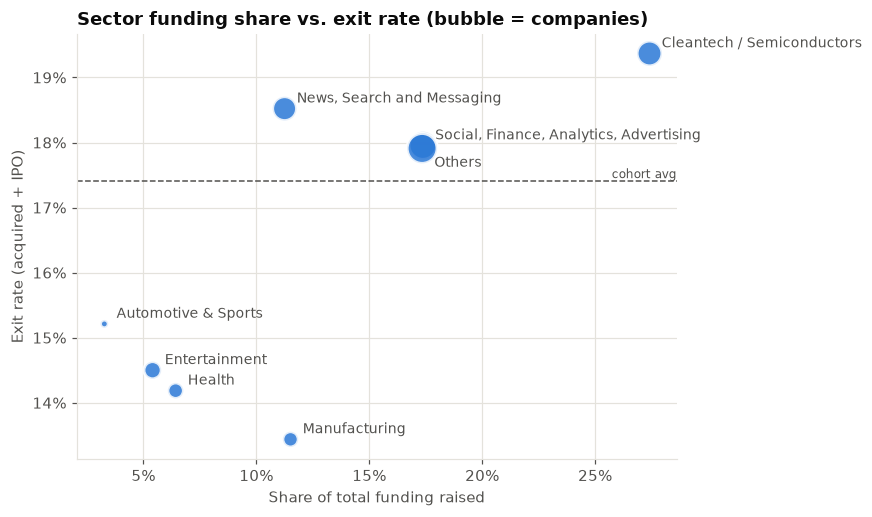

In [4]:
sector = cohort.groupby('main_sector').agg(
    companies=('exit', 'size'), exit_rate=('exit', 'mean'),
    failure_rate=('closed', 'mean'), raised_m=('total_raised_m', 'sum'))
sector['funding_share'] = sector.raised_m / sector.raised_m.sum()
sector = sector.sort_values('funding_share', ascending=False)
display(sector.style.format({'exit_rate': '{:.1%}', 'failure_rate': '{:.1%}',
                             'funding_share': '{:.1%}', 'raised_m': '{:,.0f}', 'companies': '{:,}'}))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(sector.funding_share, sector.exit_rate, s=sector.companies / 15,
           color=BLUE, alpha=0.85, edgecolor='white', linewidth=2, zorder=3)
for name, row in sector.iterrows():
    ax.annotate(name, (row.funding_share, row.exit_rate), xytext=(8, -12 if name == 'Others' else 4),
                textcoords='offset points', fontsize=9, color=INK_2)
ax.axhline(cohort.exit.mean(), color=INK_2, lw=1, ls='--')
ax.text(ax.get_xlim()[1], cohort.exit.mean(), ' cohort avg', va='bottom', ha='right', fontsize=8, color=INK_2)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Share of total funding raised'); ax.set_ylabel('Exit rate (acquired + IPO)')
ax.set_title('Sector funding share vs. exit rate (bubble = companies)')
plt.tight_layout(); plt.show()

### A2. A sturdier test: primary category level
Eight sectors are too few points for a statistical test. Repeat at the primary-category level (categories with ≥ 50 companies) and check the rank correlation between how much money a category attracts and its outcomes.

62 categories
Funding vs exit rate:    Spearman rho = +0.24 (p = 0.059)
Funding vs failure rate: Spearman rho = -0.20 (p = 0.119)


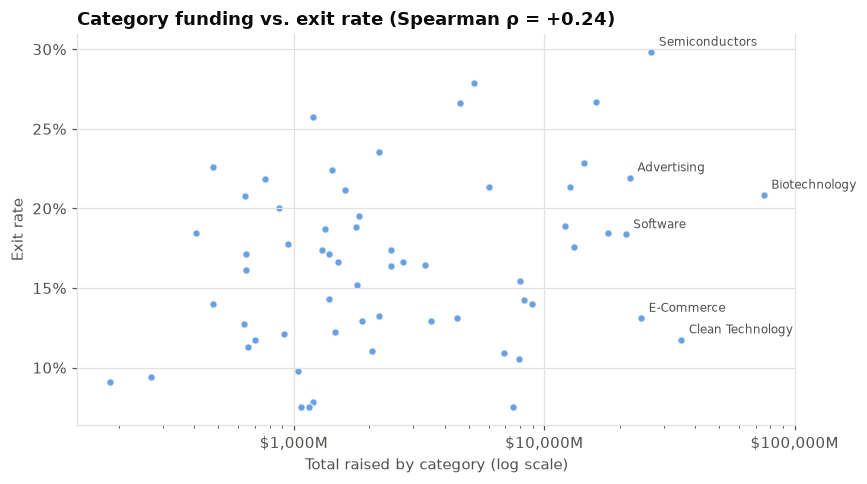

In [5]:
category = cohort.groupby('primary_sector').agg(
    companies=('exit', 'size'), exit_rate=('exit', 'mean'),
    failure_rate=('closed', 'mean'), raised_m=('total_raised_m', 'sum'))
category = category[category.companies >= 50]

rho_exit, p_exit = stats.spearmanr(category.raised_m, category.exit_rate)
rho_fail, p_fail = stats.spearmanr(category.raised_m, category.failure_rate)
print(f'{len(category)} categories')
print(f'Funding vs exit rate:    Spearman rho = {rho_exit:+.2f} (p = {p_exit:.3f})')
print(f'Funding vs failure rate: Spearman rho = {rho_fail:+.2f} (p = {p_fail:.3f})')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(category.raised_m, category.exit_rate, s=24, color=BLUE, alpha=0.7, edgecolor='white', linewidth=1)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
ax.yaxis.set_major_formatter(pct)
for name in category.raised_m.nlargest(6).index:
    r = category.loc[name]
    ax.annotate(name, (r.raised_m, r.exit_rate), xytext=(5, 4), textcoords='offset points', fontsize=8, color=INK_2)
ax.set_xlabel('Total raised by category (log scale)'); ax.set_ylabel('Exit rate')
ax.set_title(f'Category funding vs. exit rate (Spearman ρ = {rho_exit:+.2f})')
plt.tight_layout(); plt.show()

### A3. By country (English-speaking only)

,companies,exit_rate,failure_rate,raised_m
country_code,,,,
USA,"15,164",20.8%,11.8%,"392,848"
GBR,"1,309",12.4%,13.3%,"16,122"
IND,303,10.9%,9.9%,"12,853"
CAN,672,18.9%,12.6%,"8,106"
IRL,167,10.8%,9.6%,"1,401"
AUS,137,12.4%,14.6%,"1,234"
SGP,123,10.6%,17.1%,"1,125"
ZAF,38,10.5%,7.9%,200


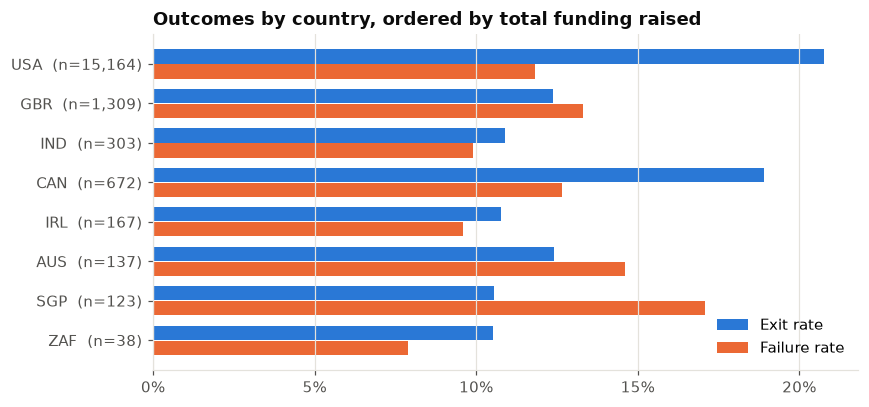

In [6]:
country = (cohort[cohort.country_code.isin(ENGLISH)]
           .groupby('country_code')
           .agg(companies=('exit', 'size'), exit_rate=('exit', 'mean'),
                failure_rate=('closed', 'mean'), raised_m=('total_raised_m', 'sum'))
           .sort_values('raised_m', ascending=False))
country = country[country.companies >= 30]
display(country.style.format({'exit_rate': '{:.1%}', 'failure_rate': '{:.1%}',
                              'raised_m': '{:,.0f}', 'companies': '{:,}'}))

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(country)); h = 0.38
ax.barh(y - h / 2, country.exit_rate, height=h - 0.02, color=BLUE, label='Exit rate')
ax.barh(y + h / 2, country.failure_rate, height=h - 0.02, color=ORANGE, label='Failure rate')
ax.set_yticks(y, [f'{c}  (n={n:,})' for c, n in zip(country.index, country.companies)])
ax.invert_yaxis(); ax.xaxis.set_major_locator(mtick.MultipleLocator(0.05)); ax.xaxis.set_major_formatter(pct); ax.grid(axis='y', visible=False)
ax.legend(frameon=False, loc='lower right')
ax.set_title('Outcomes by country, ordered by total funding raised')
plt.tight_layout(); plt.show()

### A4. By funding type, and the Spark Funds ticket
Outcome by the company's **first** funding type, and for companies that did vs. did not take a 5–15M venture round.

In [7]:
by_type = (cohort[cohort.first_type.isin(['seed', 'angel', 'venture', 'private_equity'])]
           .groupby('first_type')
           .agg(companies=('exit', 'size'), exit_rate=('exit', 'mean'), failure_rate=('closed', 'mean')))
display(by_type.style.format({'exit_rate': '{:.1%}', 'failure_rate': '{:.1%}', 'companies': '{:,}'}))

ticket = (cohort.groupby('had_5_15m_venture')
          .agg(companies=('exit', 'size'), exit_rate=('exit', 'mean'), failure_rate=('closed', 'mean'))
          .rename(index={True: 'Took a 5-15M venture round', False: 'Did not'}))
display(ticket.style.format({'exit_rate': '{:.1%}', 'failure_rate': '{:.1%}', 'companies': '{:,}'}))

,companies,exit_rate,failure_rate
first_type,,,
angel,"1,671",11.7%,20.3%
private_equity,358,29.1%,9.5%
seed,"5,684",11.5%,17.7%
venture,"13,394",21.1%,10.2%


,companies,exit_rate,failure_rate
had_5_15m_venture,,,
Did not,"17,137",13.8%,13.9%
Took a 5-15M venture round,"6,787",26.5%,8.5%


## Part B — Round funnel

One row per company with the date it first reached each stage. Seed = `funding_round_type == 'seed'`; A–D = venture rounds with that `funding_round_code`. The same 2005–2011 cohort (by first funding year) is used so later stages have had time to happen.

In [8]:
STAGES = ['Seed', 'A', 'B', 'C', 'D']
staged = rounds[rounds.funding_round_type.isin(['seed', 'venture'])].copy()
staged['stage'] = np.where(staged.funding_round_type == 'seed', 'Seed', staged.funding_round_code)
staged = staged[staged.stage.isin(STAGES)]

stage_dates = staged.groupby(['company_permalink', 'stage']).funded_at.min().unstack()[STAGES]
stage_dates = stage_dates.join(co.set_index('permalink')[['first_year', 'status', 'country_code', 'main_sector']], how='inner')
funnel_cohort = stage_dates[stage_dates.first_year.between(*COHORT)]
print(f'Funnel cohort: {len(funnel_cohort):,} companies')

Funnel cohort: 15,097 companies


### B1. Stage-to-stage conversion and time between rounds

,companies_at_start,converted,conversion,median_months
step,,,,
Seed → A,"6,597","1,419",21.5%,18
A → B,"7,277","3,114",42.8%,18
B → C,"5,002","1,872",37.4%,20
C → D,"2,714",902,33.2%,18


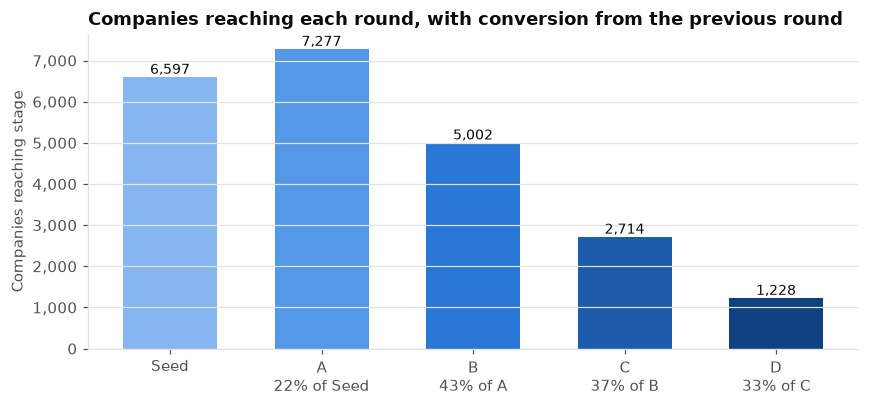

In [9]:
rows = []
for a, b in zip(STAGES, STAGES[1:]):
    reached_a = funnel_cohort[a].notna()
    reached_both = reached_a & funnel_cohort[b].notna()
    months = (funnel_cohort.loc[reached_both, b] - funnel_cohort.loc[reached_both, a]).dt.days / 30.44
    rows.append({'step': f'{a} → {b}', 'companies_at_start': reached_a.sum(),
                 'converted': reached_both.sum(), 'conversion': reached_both.sum() / reached_a.sum(),
                 'median_months': months[months > 0].median()})
conversion = pd.DataFrame(rows).set_index('step')
display(conversion.style.format({'conversion': '{:.1%}', 'median_months': '{:.0f}',
                                 'companies_at_start': '{:,}', 'converted': '{:,}'}))

reached = funnel_cohort[STAGES].notna().sum()
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = ['Seed'] + [f'{b}\n{c:.0%} of {a}' for (a, b), c in zip(zip(STAGES, STAGES[1:]), conversion.conversion)]
bars = ax.bar(labels, reached.values, color=FUNNEL, width=0.62)
for bar, n in zip(bars, reached.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f'{n:,}', ha='center', va='bottom', fontsize=9, color=INK)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}')); ax.grid(axis='x', visible=False)
ax.set_ylabel('Companies reaching stage')
ax.set_title('Companies reaching each round, with conversion from the previous round')
plt.tight_layout(); plt.show()

### B2. Round size by stage: where does a 5–15M ticket fit?

,count,25%,50%,75%
stage,,,,
Seed,"23,603.0",0.1,0.3,1.0
A,"12,702.0",2.0,4.2,8.0
B,"8,083.0",5.0,10.0,16.0
C,"4,217.0",8.0,14.8,25.0
D,"1,916.0",10.0,18.0,33.0


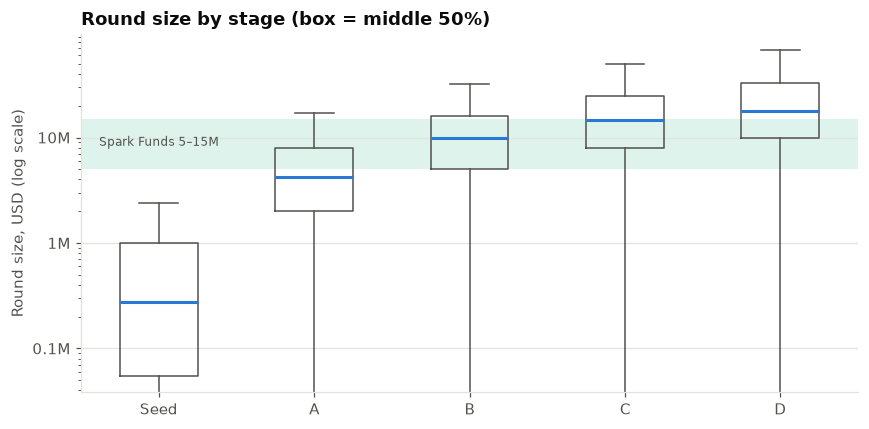

Which stage are 5-15M rounds?
stage
Seed     1.8%
A       41.8%
B       35.2%
C       15.6%
D        5.6%
Name: proportion, dtype: str


In [10]:
sizes = staged.dropna(subset=['amount_m'])
display(sizes.groupby('stage').amount_m.describe(percentiles=[.25, .5, .75])
        .loc[STAGES, ['count', '25%', '50%', '75%']].style.format('{:,.1f}'))

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhspan(5, 15, color=AQUA, alpha=0.15, lw=0)
ax.text(1, 9, 'Spark Funds 5–15M', va='center', ha='center', fontsize=8, color=INK_2)
ax.boxplot([sizes.loc[sizes.stage == s, 'amount_m'] for s in STAGES], tick_labels=STAGES, showfliers=False,
           widths=0.5, medianprops=dict(color=BLUE, lw=2), boxprops=dict(color=INK_2),
           whiskerprops=dict(color=INK_2), capprops=dict(color=INK_2))
ax.set_yscale('log'); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:g}M'))
ax.grid(axis='x', visible=False); ax.set_ylabel('Round size, USD (log scale)')
ax.set_title('Round size by stage (box = middle 50%)')
plt.tight_layout(); plt.show()

band_mix = sizes[sizes.amount_m.between(5, 15)].stage.value_counts(normalize=True).reindex(STAGES)
print('Which stage are 5-15M rounds?'); print(band_mix.map('{:.1%}'.format))

### B3. Outcome by the furthest stage reached

,companies,exit_rate,failure_rate
furthest,,,
Seed,"5,005",9.4%,20.0%
A,"4,000",19.5%,14.7%
B,"3,052",24.4%,10.0%
C,"1,812",28.2%,6.8%
D,"1,228",30.8%,3.9%


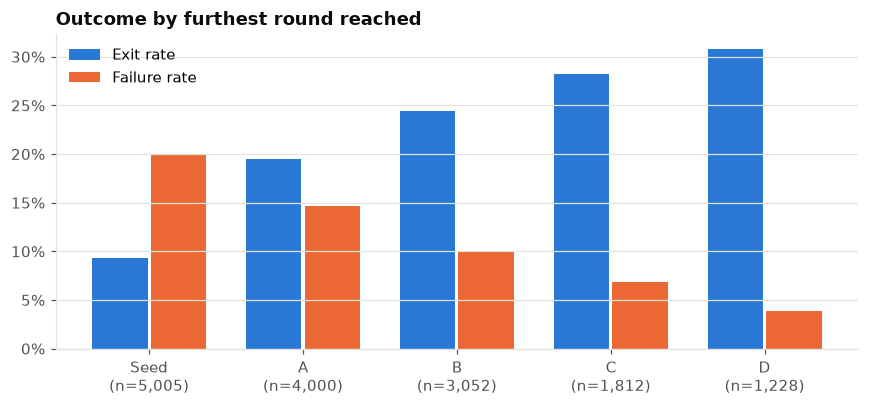

In [11]:
funnel_cohort = funnel_cohort.assign(
    furthest=funnel_cohort[STAGES].notna().iloc[:, ::-1].idxmax(axis=1),
    exit=funnel_cohort.status.isin(['acquired', 'ipo']),
    closed=funnel_cohort.status.eq('closed'))
furthest = (funnel_cohort.groupby('furthest')
            .agg(companies=('exit', 'size'), exit_rate=('exit', 'mean'), failure_rate=('closed', 'mean'))
            .reindex(STAGES))
display(furthest.style.format({'exit_rate': '{:.1%}', 'failure_rate': '{:.1%}', 'companies': '{:,}'}))

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(STAGES)); w = 0.38
ax.bar(x - w / 2, furthest.exit_rate, width=w - 0.02, color=BLUE, label='Exit rate')
ax.bar(x + w / 2, furthest.failure_rate, width=w - 0.02, color=ORANGE, label='Failure rate')
ax.set_xticks(x, [f'{s}\n(n={n:,})' for s, n in zip(STAGES, furthest.companies)])
ax.yaxis.set_major_formatter(pct); ax.grid(axis='x', visible=False)
ax.legend(frameon=False)
ax.set_title('Outcome by furthest round reached')
plt.tight_layout(); plt.show()

## Findings
Cohort: 23,924 companies first funded 2005–2011. Overall: **17.4% exited**, **12.4% closed**.

**A. Does following the crowd pay off? Partly. It depends on the dimension.**

- **Sector: weak support.** The most crowded sector, Cleantech / Semiconductors (27% of funding), also has the highest exit rate (19.4%) and a low failure rate (8.3%). Smaller sectors (Manufacturing, Health, Entertainment) exit below average. But at category level the link is weak: Spearman ρ = +0.24 with exits (p = 0.06) and −0.20 with failures (p = 0.12). Crowded categories are not worse, but popularity on its own is a weak signal. One exception: *News, Search and Messaging* has the **highest failure rate (18.8%)** despite above-average exits, so it is a high-variance sector.
- **Country: the crowd works for the USA only.** The USA has the most funding and the best exit rate (20.8%). Part 1's next picks, **GBR (12.4% exit, 13.3% closed)** and **IND (10.9% exit)**, sit well below **Canada (18.9% exit)**, which attracts less money. Following the money beyond the USA would not have picked the best outcomes.
- **Funding type: venture beats seed/angel.** Companies whose first round was venture exit at 21.1% vs ~11.5% for seed/angel, which also fail about twice as often. Private equity looks best (29.1%), but the sample is small (n = 358) and the companies are more mature.
- **The 5–15M ticket:** companies that took a 5–15M venture round exited at **26.5% vs 13.8%** and closed at **8.5% vs 13.9%**. This shows correlation, not causation: raising that round is itself a sign of traction.

**B. The funnel: where a 5–15M ticket enters**

- Conversion is **21.5% Seed → A**, **42.8% A → B**, **37.4% B → C** and **33.2% C → D**. The median gap is **18–20 months** at every step.
- **77% of 5–15M rounds are Series A (41.8%) or B (35.2%).** Median round size is 4.2M at A and 10M at B, so B is the natural fit for the fund's range.
- Outcomes improve steadily with each round a company reaches: from **9.4% exit / 20.0% failure** for companies that stop at Seed, to **24.4% / 10.0%** at B and **30.8% / 3.9%** at D.

**What this means for Spark Funds:** keep the venture focus. Target **Series B** within the 5–15M range rather than early A, because B companies have already passed the steepest drop-off. Outside the USA, rank countries by outcomes, not by total funding. On those numbers, Canada is a stronger second market than GBR or IND.

*Limitations: `status` is a 2015 snapshot; Crunchbase over-represents US and well-funded companies; seed rounds are under-reported, which pushes Seed → A conversion down. Many companies enter at Series A, which is why more companies reach A than Seed.*

## Export for Power BI (page 2)
Two tidy tables for the dashboard: one row per company, and one row per company × stage.

In [12]:
furthest_all = stage_dates[STAGES].notna().iloc[:, ::-1].idxmax(axis=1).rename('furthest_stage')
company_out = co.merge(furthest_all, left_on='permalink', right_index=True, how='left')
company_out = company_out[['permalink', 'name', 'country_code', 'main_sector', 'primary_sector', 'status',
                           'first_year', 'first_type', 'total_raised_m', 'n_rounds', 'had_5_15m_venture',
                           'furthest_stage', 'exit', 'closed']]
company_out.to_csv(DATA / 'company_outcomes.csv', index=False)

stage_out = (staged.groupby(['company_permalink', 'stage'])
             .agg(first_funded=('funded_at', 'min'), amount_m=('amount_m', lambda x: x.sum(min_count=1)))
             .reset_index())
stage_out['stage_order'] = stage_out.stage.map({s: i for i, s in enumerate(STAGES)})
stage_out.to_csv(DATA / 'company_stages.csv', index=False)
print(f'company_outcomes.csv: {len(company_out):,} rows   company_stages.csv: {len(stage_out):,} rows')

company_outcomes.csv: 66,368 rows   company_stages.csv: 52,500 rows
